# Diabetes Prediction Using Fuzzy Logic and Ensemble Machine Learning

Educational implementation inspired by the 2026 paper:
**Integration of Machine Learning and Fuzzy Logic for Diabetes Prediction Using a Fused Ensemble Approach**

This notebook trains SVM, ANN (MLP), Random Forest, and Gradient Boosting, then combines their test-set probabilities using a Mamdani-style fuzzy inference system.

**Important:** This is a reproducible educational implementation, not the authors' official code or an exact reproduction of their experimental setup. It is not a medical diagnostic tool.

## 1. Install required libraries

In [1]:
!pip -q install ucimlrepo scikit-fuzzy

## 2. Import libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

import skfuzzy as fuzz
from skfuzzy import control as ctrl

## 3. Load the UCI Early Stage Diabetes dataset

In [5]:
# UCI dataset ID 529
dataset = fetch_ucirepo(id=529)

X = dataset.data.features.copy()
y_df = dataset.data.targets.copy()

print("Feature shape:", X.shape)
print("Target shape:", y_df.shape)
display(X.head())
display(y_df.head())

# Clean column names for easier handling
X.columns = [str(c).strip().lower().replace(" ", "_") for c in X.columns]

# Convert target values (usually Positive/Negative) to 1/0
target = y_df.iloc[:, 0].astype(str).str.strip().str.lower()
positive_labels = {"positive", "pos", "yes", "1", "diabetes", "diabetic"}
y = target.map(lambda v: 1 if v in positive_labels or "positive" in v else 0)

if y.nunique() != 2:
    raise ValueError(f"Expected a binary target; found labels: {sorted(target.unique())}")

print("Class counts (0 = non-diabetic, 1 = positive):")
print(y.value_counts().sort_index())

Feature shape: (520, 16)
Target shape: (520, 1)


,age,gender,polyuria,polydipsia,sudden_weight_loss,weakness,polyphagia,genital_thrush,visual_blurring,itching,irritability,delayed_healing,partial_paresis,muscle_stiffness,alopecia,obesity
0,40,Male,No,Yes,No,Yes,No,No,No,Yes,No,Yes,No,Yes,Yes,Yes
1,58,Male,No,No,No,Yes,No,No,Yes,No,No,No,Yes,No,Yes,No
2,41,Male,Yes,No,No,Yes,Yes,No,No,Yes,No,Yes,No,Yes,Yes,No
3,45,Male,No,No,Yes,Yes,Yes,Yes,No,Yes,No,Yes,No,No,No,No
4,60,Male,Yes,Yes,Yes,Yes,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes


,class
0,Positive
1,Positive
2,Positive
3,Positive
4,Positive


Class counts (0 = non-diabetic, 1 = positive):
class
0    200
1    320
Name: count, dtype: int64


## 4. Split the data and prepare preprocessing

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Numeric and categorical columns are detected from the training data
numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Training records: 364
Testing records: 156
Numeric columns: ['age']
Categorical columns: ['gender', 'polyuria', 'polydipsia', 'sudden_weight_loss', 'weakness', 'polyphagia', 'genital_thrush', 'visual_blurring', 'itching', 'irritability', 'delayed_healing', 'partial_paresis', 'muscle_stiffness', 'alopecia', 'obesity']


## 5. Train the four machine-learning models

In [7]:
models = {
    "SVM": SVC(probability=True, kernel="rbf", random_state=42),
    "ANN": MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight="balanced"
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

trained_models = {}

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(f"{name}: trained")

SVM: trained
ANN: trained
Random Forest: trained
Gradient Boosting: trained


## 6. Create a Mamdani-style fuzzy fusion system

For a transparent, compact implementation, the four model probabilities are summarized into:

- **Mean probability:** average predicted probability across the four classifiers.
- **Disagreement:** standard deviation of the four probabilities.

Fuzzy rules then map these two values to a final risk score. This is a reasonable educational fuzzy-fusion design, but it may differ from the exact membership functions and rules in the published paper.

In [8]:
# Fuzzy inputs and output, all scaled to [0, 1]
mean_prob = ctrl.Antecedent(np.arange(0, 1.01, 0.01), "mean_prob")
disagreement = ctrl.Antecedent(np.arange(0, 0.501, 0.005), "disagreement")
risk = ctrl.Consequent(np.arange(0, 1.01, 0.01), "risk")

# Membership functions for average predicted probability
mean_prob["low"] = fuzz.trapmf(mean_prob.universe, [0.0, 0.0, 0.25, 0.45])
mean_prob["medium"] = fuzz.trimf(mean_prob.universe, [0.25, 0.50, 0.75])
mean_prob["high"] = fuzz.trapmf(mean_prob.universe, [0.55, 0.75, 1.0, 1.0])

# Membership functions for disagreement between models
disagreement["low"] = fuzz.trapmf(disagreement.universe, [0.0, 0.0, 0.05, 0.15])
disagreement["medium"] = fuzz.trimf(disagreement.universe, [0.08, 0.22, 0.36])
disagreement["high"] = fuzz.trapmf(disagreement.universe, [0.25, 0.35, 0.50, 0.50])

# Membership functions for final fuzzy risk score
risk["low"] = fuzz.trapmf(risk.universe, [0.0, 0.0, 0.25, 0.45])
risk["medium"] = fuzz.trimf(risk.universe, [0.25, 0.50, 0.75])
risk["high"] = fuzz.trapmf(risk.universe, [0.55, 0.75, 1.0, 1.0])

rules = [
    ctrl.Rule(mean_prob["low"] & disagreement["low"], risk["low"]),
    ctrl.Rule(mean_prob["low"] & disagreement["medium"], risk["low"]),
    ctrl.Rule(mean_prob["low"] & disagreement["high"], risk["medium"]),

    ctrl.Rule(mean_prob["medium"] & disagreement["low"], risk["medium"]),
    ctrl.Rule(mean_prob["medium"] & disagreement["medium"], risk["medium"]),
    ctrl.Rule(mean_prob["medium"] & disagreement["high"], risk["medium"]),

    ctrl.Rule(mean_prob["high"] & disagreement["low"], risk["high"]),
    ctrl.Rule(mean_prob["high"] & disagreement["medium"], risk["high"]),
    ctrl.Rule(mean_prob["high"] & disagreement["high"], risk["medium"]),
]

fuzzy_system = ctrl.ControlSystem(rules)
print("Fuzzy inference system created with", len(rules), "rules.")

Fuzzy inference system created with 9 rules.


## 7. Predict with individual models and fuzzy fusion

In [9]:
# Probability that each model assigns to class 1 (positive/diabetes)
probabilities = pd.DataFrame({
    name: model.predict_proba(X_test)[:, 1]
    for name, model in trained_models.items()
}, index=X_test.index)

mean_values = probabilities.mean(axis=1)
disagreement_values = probabilities.std(axis=1)

fuzzy_scores = []
for avg, disagree in zip(mean_values, disagreement_values):
    sim = ctrl.ControlSystemSimulation(fuzzy_system)
    sim.input["mean_prob"] = float(np.clip(avg, 0, 1))
    sim.input["disagreement"] = float(np.clip(disagree, 0, 0.5))
    sim.compute()
    fuzzy_scores.append(sim.output["risk"])

# Threshold 0.6 is included as an experimental decision threshold.
# It is not guaranteed to reproduce the paper's exact results.
FUZZY_THRESHOLD = 0.60
fuzzy_predictions = (np.array(fuzzy_scores) >= FUZZY_THRESHOLD).astype(int)

print("First five model probabilities:")
display(probabilities.head())
print("First five fuzzy scores:", np.round(fuzzy_scores[:5], 3))

First five model probabilities:


,SVM,ANN,Random Forest,Gradient Boosting
336,0.028880,0.005826,0.015,0.052529
378,0.991662,0.999993,0.980,0.990042
252,0.999997,0.999997,1.000,0.999363
273,0.028009,0.012999,0.015,0.082510
434,0.999999,1.000000,0.995,0.998770


First five fuzzy scores: [0.18 0.82 0.82 0.18 0.82]


## 8. Evaluate model performance

In [10]:
def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

results = []

for name, model in trained_models.items():
    pred = model.predict(X_test)
    results.append(calculate_metrics(y_test, pred, name))

results.append(calculate_metrics(y_test, fuzzy_predictions, "Fuzzy Fusion"))

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

print("\nFuzzy Fusion classification report:")
print(classification_report(
    y_test, fuzzy_predictions,
    target_names=["Non-diabetic class", "Positive class"],
    zero_division=0
))

,Accuracy,Precision,Recall,F1-score
Model,,,,
SVM,0.9615,0.9787,0.9583,0.9684
ANN,0.9872,0.9896,0.9896,0.9896
Random Forest,0.9872,0.9896,0.9896,0.9896
Gradient Boosting,0.9872,0.9896,0.9896,0.9896
Fuzzy Fusion,0.9679,0.9892,0.9583,0.9735



Fuzzy Fusion classification report:
                    precision    recall  f1-score   support

Non-diabetic class       0.94      0.98      0.96        60
    Positive class       0.99      0.96      0.97        96

          accuracy                           0.97       156
         macro avg       0.96      0.97      0.97       156
      weighted avg       0.97      0.97      0.97       156



## 9. Plot model comparison and confusion matrix

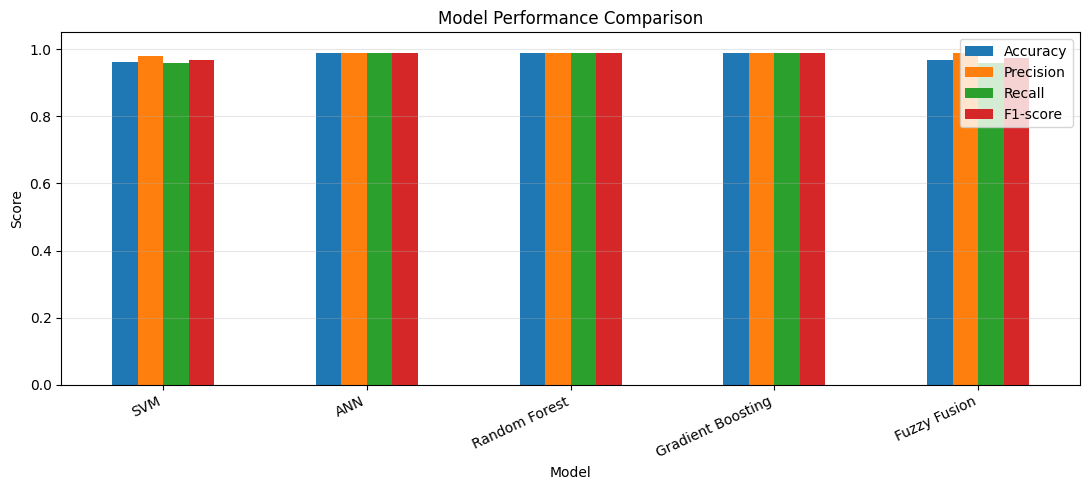

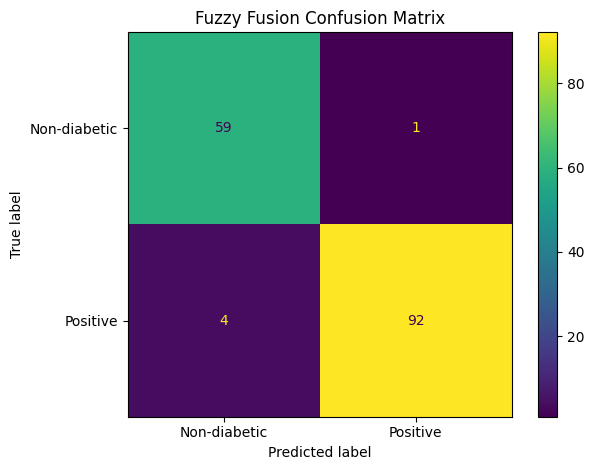

In [11]:
results_df[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(11, 5), ylim=(0, 1.05)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, fuzzy_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-diabetic", "Positive"]
)
disp.plot(values_format="d")
plt.title("Fuzzy Fusion Confusion Matrix")
plt.tight_layout()
plt.show()

## 10. Try one test patient

This example uses an actual row from the held-out test set, so all feature columns and data types match the training data. It demonstrates the model output only; it is **not a medical diagnosis**.

In [12]:
sample = X_test.iloc[[0]]
print("Sample patient features:")
display(sample)

sample_probs = {
    name: float(model.predict_proba(sample)[0, 1])
    for name, model in trained_models.items()
}
sample_mean = float(np.mean(list(sample_probs.values())))
sample_disagreement = float(np.std(list(sample_probs.values())))

sim = ctrl.ControlSystemSimulation(fuzzy_system)
sim.input["mean_prob"] = float(np.clip(sample_mean, 0, 1))
sim.input["disagreement"] = float(np.clip(sample_disagreement, 0, 0.5))
sim.compute()
sample_fuzzy_score = float(sim.output["risk"])

print("Individual model probabilities:", sample_probs)
print("Mean probability:", round(sample_mean, 3))
print("Model disagreement:", round(sample_disagreement, 3))
print("Fuzzy risk score:", round(sample_fuzzy_score, 3))
print("Fuzzy model class:", "Positive class" if sample_fuzzy_score >= FUZZY_THRESHOLD else "Non-positive class")
print("Actual dataset label:", int(y_test.iloc[0]))

Sample patient features:


,age,gender,polyuria,polydipsia,sudden_weight_loss,weakness,polyphagia,genital_thrush,visual_blurring,itching,irritability,delayed_healing,partial_paresis,muscle_stiffness,alopecia,obesity
336,42,Male,No,No,No,No,No,No,No,No,No,No,No,No,Yes,No


Individual model probabilities: {'SVM': 0.028880466876447353, 'ANN': 0.005826473465899896, 'Random Forest': 0.015, 'Gradient Boosting': 0.05252854150735619}
Mean probability: 0.026
Model disagreement: 0.018
Fuzzy risk score: 0.18
Fuzzy model class: Non-positive class
Actual dataset label: 0


## 11. Save results

The following cell saves test-set predictions and the metric table to CSV files.

In [13]:
prediction_output = probabilities.copy()
prediction_output["mean_probability"] = mean_values
prediction_output["model_disagreement"] = disagreement_values
prediction_output["fuzzy_score"] = fuzzy_scores
prediction_output["fuzzy_prediction"] = fuzzy_predictions
prediction_output["actual_label"] = y_test

prediction_output.to_csv("diabetes_fuzzy_predictions.csv", index=True)
results_df.to_csv("diabetes_model_metrics.csv")

print("Saved diabetes_fuzzy_predictions.csv")
print("Saved diabetes_model_metrics.csv")

Saved diabetes_fuzzy_predictions.csv
Saved diabetes_model_metrics.csv


## References

1. Kathiria, P., Chavda, N., Bhatt, M., Chavda, N., Khanpara, P., & Patel, U. (2026). *Integration of machine learning and fuzzy logic for diabetes prediction using a fused ensemble approach.* Discover Artificial Intelligence. https://doi.org/10.1007/s44163-026-01648-8
2. UCI Machine Learning Repository. *Early Stage Diabetes Risk Prediction.* https://archive.ics.uci.edu/dataset/529/early